# Dog vs Cat Image Classifier

**Goal:** Build and compare three binary image classifiers (dog vs. cat) using TensorFlow/Keras:

| # | Approach | Backbone |
|---|----------|----------|
| 1 | Custom CNN trained from scratch | – |
| 2 | Feature extraction (linear probing, frozen backbone) | MobileNetV2 (ImageNet) |
| 3 | Full fine-tuning (all layers trainable) | EfficientNetB0 (ImageNet) |

**Dataset:** [laxmimerit/dog-cat-full-dataset](https://github.com/laxmimerit/dog-cat-full-dataset) (cloned from GitHub).
**Notebook outline**
1. Dataset preparation
2. Data augmentation
3. Custom CNN
4. Transfer learning – feature extraction
5. Full fine-tuning
6. Model comparison
7. Error analysis

> **Before running:** `Runtime → Change runtime type → GPU (T4)`.

In [ ]:
# Imports
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Global hyperparameters
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
AUTOTUNE   = tf.data.AUTOTUNE
DATA_DIR   = "dog-cat-full-dataset/data"

print("TensorFlow version:", tf.__version__)
print("GPUs available    :", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs available    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Dataset Preparation


In [ ]:
# Clone the dataset
!test -d dog-cat-full-dataset || git clone https://github.com/laxmimerit/dog-cat-full-dataset.git
!ls dog-cat-full-dataset/data

Cloning into 'dog-cat-full-dataset'...
remote: Enumerating objects: 25059, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 25059 (delta 4), reused 6 (delta 2), pack-reused 25048 (from 1)
Receiving objects: 100% (25059/25059), 541.54 MiB | 19.69 MiB/s, done.
Resolving deltas: 100% (21/21), done.
Updating files: 100% (24990/24990), done.
test  train


In [ ]:
train_dir = os.path.join(DATA_DIR, "train")
test_dir  = os.path.join(DATA_DIR, "test")

raw_train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

raw_val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
)

raw_test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

Found 19989 files belonging to 2 classes.
Using 15992 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.


In [ ]:
# Class names and number of samples
class_names = raw_train_ds.class_names
print("Class names:", class_names, "-> label 0 =", class_names[0], "| label 1 =", class_names[1])

n_train, n_val, n_test = len(raw_train_ds.file_paths), len(raw_val_ds.file_paths), len(raw_test_ds.file_paths)
print(f"Training samples  : {n_train}")
print(f"Validation samples: {n_val}")
print(f"Test samples      : {n_test}")
print(f"Train/Val split   : {n_train/(n_train+n_val):.0%} / {n_val/(n_train+n_val):.0%}")

Class names: ['cats', 'dogs'] -> label 0 = cats | label 1 = dogs
Training samples  : 15992
Validation samples: 3997
Test samples      : 5000
Train/Val split   : 80% / 20%


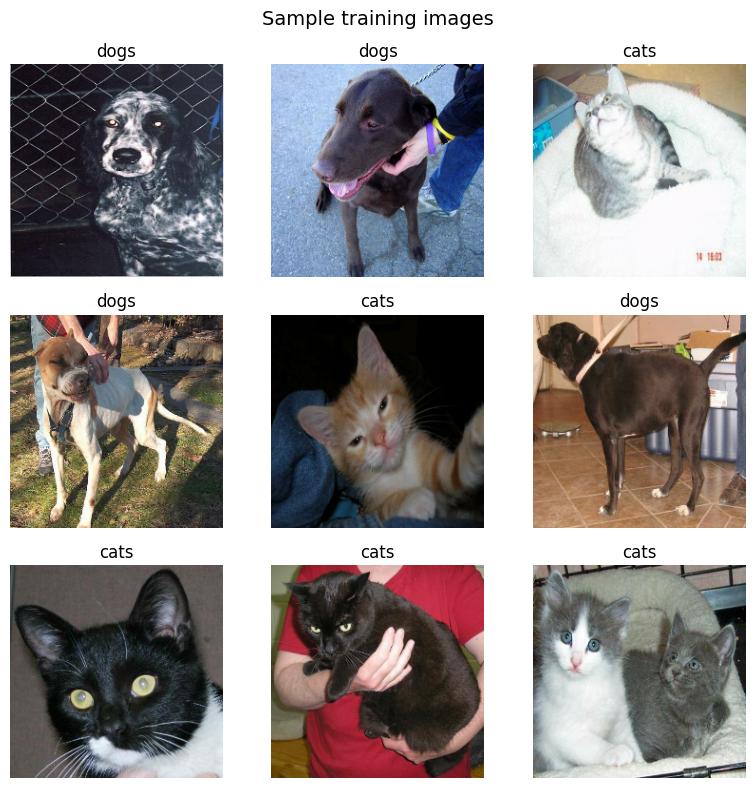

In [ ]:
# A few training images
plt.figure(figsize=(8, 8))
for images, labels in raw_train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.suptitle("Sample training images", fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
normalization_layer = layers.Rescaling(1.0 / 255)

def normalize(images, labels):
    "Scale pixel values from [0, 255] to [0, 1]."
    return normalization_layer(images), labels

# Normalize + prefetch so data loading overlaps with model execution
train_ds = raw_train_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = raw_val_ds.map(normalize,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds  = raw_test_ds.map(normalize,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Sanity check
imgs, lbls = next(iter(train_ds))
print("Batch shape :", imgs.shape, "| label shape:", lbls.shape)
print(f"Pixel range : min={imgs.numpy().min():.3f}, max={imgs.numpy().max():.3f}")

Batch shape : (32, 224, 224, 3) | label shape: (32, 1)
Pixel range : min=0.000, max=1.000


# Data Augmentation


In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ],
    name="data_augmentation",
)
data_augmentation.summary()

Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def augment(images, labels):
    "Apply random augmentation (training=True activates the random layers)."
    return data_augmentation(images, training=True), labels

train_aug_ds = (
    raw_train_ds
    .map(augment, num_parallel_calls=AUTOTUNE)     # augment on raw [0, 255] pixels
    .map(normalize, num_parallel_calls=AUTOTUNE)   # then scale to [0, 1]
    .prefetch(AUTOTUNE)
)
# val_ds and test_ds are NOT augmented.
print("train_aug_ds -> used for training | val_ds / test_ds -> clean, un-augmented")

train_aug_ds -> used for training | val_ds / test_ds -> clean, un-augmented


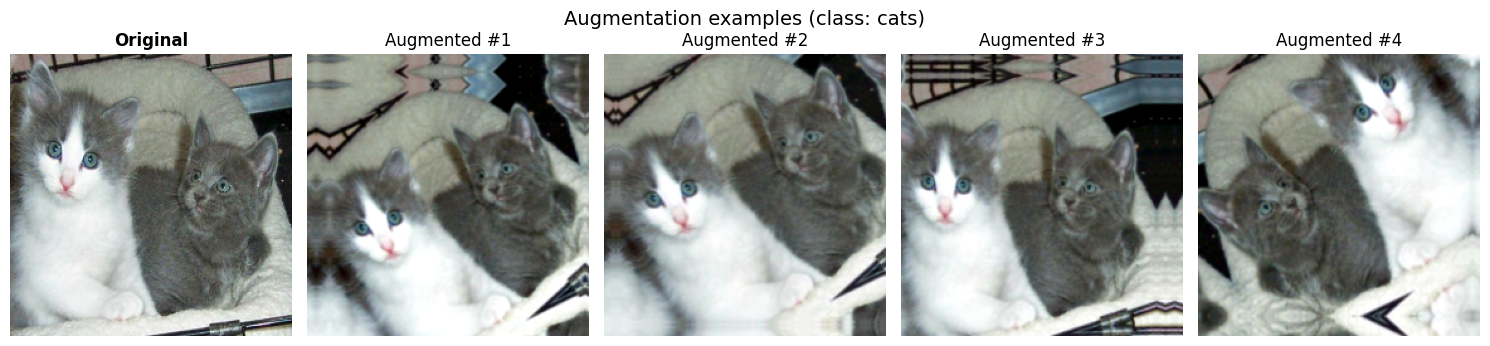

In [ ]:
# Original image vs. four augmented versions
images, labels = next(iter(raw_train_ds.take(1)))
original = images[0]

plt.figure(figsize=(15, 3.5))
ax = plt.subplot(1, 5, 1)
plt.imshow(original.numpy().astype("uint8"))
plt.title("Original", fontweight="bold"); plt.axis("off")

for i in range(4):
    aug_img = data_augmentation(tf.expand_dims(original, 0), training=True)[0]
    plt.subplot(1, 5, i + 2)
    plt.imshow(aug_img.numpy().astype("uint8"))
    plt.title(f"Augmented #{i+1}"); plt.axis("off")

plt.suptitle(f"Augmentation examples (class: {class_names[int(labels[0][0])]})", fontsize=14)
plt.tight_layout(); plt.show()

In [ ]:
def make_early_stopping():
    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

def plot_history(history, metric, title):
    "Plot training vs. validation curves for a given metric ('accuracy' or 'loss')."
    epochs = range(1, len(history.history[metric]) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history.history[metric], "o-", label=f"Training {metric}")
    plt.plot(epochs, history.history[f"val_{metric}"], "s-", label=f"Validation {metric}")
    plt.title(f"{title} – {metric.capitalize()}")
    plt.xlabel("Epoch"); plt.ylabel(metric.capitalize())
    plt.grid(alpha=0.3); plt.legend(); plt.show()

MAX_EPOCHS = 30

# Custom CNN Model

**Architecture:** 4 convolutional blocks (32 → 64 → 128 → 256 filters). Each block = 2 × (`Conv2D` → `BatchNorm` → `ReLU`) → `MaxPooling2D` → `Dropout(0.25)`.
The head is `GlobalAveragePooling2D` → `Dense(128)` → `BatchNorm` → `Dropout(0.5)` → `Dense(1, sigmoid)`.

Global average pooling keeps the parameter count small compared to `Flatten`, which helps against overfitting.

In [ ]:
def conv_block(x, filters, dropout_rate=0.25):
    "Conv -> BN -> ReLU (x2) -> MaxPool -> Dropout."
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Dropout(dropout_rate)(x)
    return x

def build_custom_cnn(input_shape=(224, 224, 3)):
    inputs = keras.Input(shape=input_shape)
    x = inputs
    for filters in (32, 64, 128, 256):          # 4 convolutional blocks
        x = conv_block(x, filters)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)   # sigmoid for binary classification
    return keras.Model(inputs, outputs, name="custom_cnn")

custom_cnn = build_custom_cnn()
custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,545 (4.61 MB)

 Trainable params: 1,206,369 (4.60 MB)

 Non-trainable params: 2,176 (8.50 KB)

# Compile

- **Optimizer:** Adam (lr = 1e-3) – adaptive and a solid default when training from scratch.
- **Loss:** binary cross-entropy – matches the single sigmoid output.
- **Metric:** accuracy.

In [ ]:
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
# Train with EarlyStopping
early_stopping = make_early_stopping()

history_cnn = custom_cnn.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=[early_stopping],
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 292s 517ms/step - accuracy: 0.5911 - loss: 0.7121 - val_accuracy: 0.5997 - val_loss: 0.6879
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 235s 468ms/step - accuracy: 0.6346 - loss: 0.6430 - val_accuracy: 0.5832 - val_loss: 0.6669
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 260s 465ms/step - accuracy: 0.6736 - loss: 0.6110 - val_accuracy: 0.6317 - val_loss: 0.6625
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 259s 459ms/step - accuracy: 0.6942 - loss: 0.5870 - val_accuracy: 0.6813 - val_loss: 0.6095
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 236s 470ms/step - accuracy: 0.7044 - loss: 0.5728 - val_accuracy: 0.6635 - val_loss: 0.6295
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 262s 470ms/step - accuracy: 0.7182 - loss: 0.5531 - val_accuracy: 0.6790 - val_loss: 0.6054
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 236s 470ms/step - accuracy: 0.7312 - loss: 0.5334 - val_accuracy: 0.7253 - val_loss: 0.5602
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 231s 461ms/step - accuracy: 0.7526 -

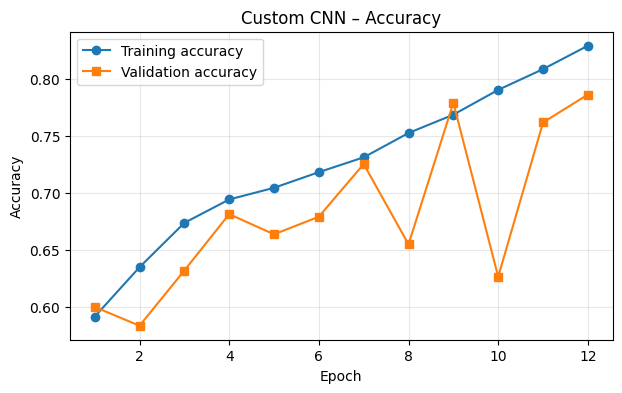

In [ ]:
# Training vs. validation accuracy
plot_history(history_cnn, "accuracy", "Custom CNN")

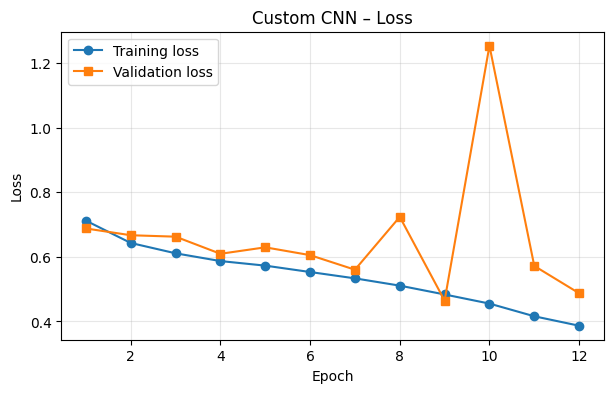

In [ ]:
# Training vs. validation loss
plot_history(history_cnn, "loss", "Custom CNN")

# Transfer Learning – Feature Extraction (Linear Probing)

**Backbone:** `MobileNetV2` pretrained on ImageNet.

Steps: load ImageNet weights → remove the original 1000-class classifier (`include_top=False`) → freeze the backbone → add a new classification head → train **only** the head.

> MobileNetV2 expects pixels in **[-1, 1]**. Our datasets are in [0, 1], so a `Rescaling(scale=2, offset=-1)` layer is placed at the start of the model (`x * 2 - 1`).

In [ ]:
# Load pretrained MobileNetV2 without the top (classifier) layers
base_fe = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

# Freeze every backbone layer
base_fe.trainable = False
print("Backbone layers:", len(base_fe.layers),
      "| trainable layers:", sum(l.trainable for l in base_fe.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Backbone layers: 154 | trainable layers: 0


In [ ]:
# New classification head
def build_feature_extractor():
    inputs = keras.Input(shape=(224, 224, 3))
    x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)   # [0,1] -> [-1,1] for MobileNetV2
    x = base_fe(x, training=False)    # training=False keeps frozen BatchNorm layers in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_feature_extraction")

feature_model = build_feature_extractor()
feature_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
feature_model.summary()

trainable   = sum(int(np.prod(w.shape)) for w in feature_model.trainable_weights)
nontrainable = sum(int(np.prod(w.shape)) for w in feature_model.non_trainable_weights)
print(f"Trainable params (new head only): {trainable:,}")
print(f"Non-trainable params (frozen)   : {nontrainable:,}")

Model: "mobilenetv2_feature_extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable params (new head only): 164,097
Non-trainable params (frozen)   : 2,257,984


In [ ]:
# Train only the new head (with EarlyStopping)
early_stopping = make_early_stopping()

history_fe = feature_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=[early_stopping],
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 243s 458ms/step - accuracy: 0.9662 - loss: 0.0891 - val_accuracy: 0.9865 - val_loss: 0.0428
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 219s 437ms/step - accuracy: 0.9737 - loss: 0.0692 - val_accuracy: 0.9865 - val_loss: 0.0382
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 215s 429ms/step - accuracy: 0.9759 - loss: 0.0630 - val_accuracy: 0.9867 - val_loss: 0.0391
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 214s 427ms/step - accuracy: 0.9782 - loss: 0.0586 - val_accuracy: 0.9847 - val_loss: 0.0460
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 217s 432ms/step - accuracy: 0.9804 - loss: 0.0531 - val_accuracy: 0.9872 - val_loss: 0.0362
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 263s 434ms/step - accuracy: 0.9794 - loss: 0.0518 - val_accuracy: 0.9877 - val_loss: 0.0424
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 216s 431ms/step - accuracy: 0.9800 - loss: 0.0510 - val_accuracy: 0.9862 - val_loss: 0.0389
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 219s 438ms/step - accuracy: 0.9798 -

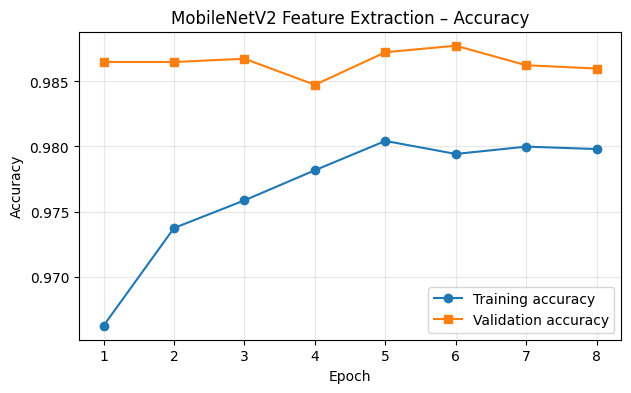

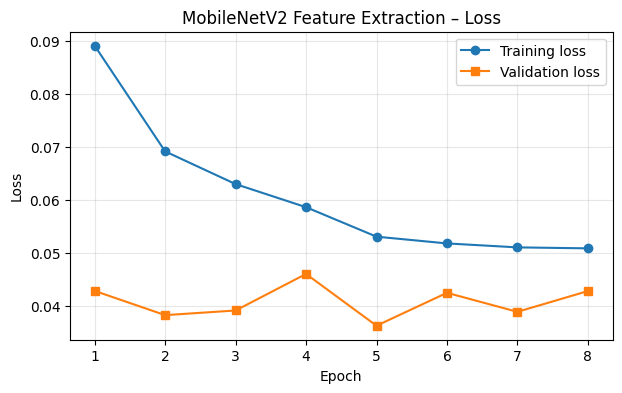

In [ ]:
plot_history(history_fe, "accuracy", "MobileNetV2 Feature Extraction")
plot_history(history_fe, "loss", "MobileNetV2 Feature Extraction")

# Why is freezing the backbone useful?

1. **Reuses powerful pretrained features.** The backbone was trained on ImageNet (1.2M images), which already contains many dog and cat classes. Its edge, texture, and shape detectors transfer directly to this task, so we don't need to relearn them.
2. **Far fewer trainable parameters.** Only the small head (~160K parameters) is updated, while ~2.2M backbone parameters stay fixed. This lowers the risk of overfitting, especially on smaller datasets.
3. **Faster and cheaper training.** No gradients or optimizer states are needed for the backbone, so epochs are quicker and memory use is lower.
4. **Protects the pretrained weights.** A randomly initialized head produces large, noisy gradients early in training. If the backbone were trainable, these gradients could destroy the good pretrained features ("catastrophic forgetting"). Freezing avoids this.
5. **Stable and reproducible.** Keeping `BatchNormalization` layers in inference mode preserves the ImageNet statistics, which gives smoother and more predictable training.

# Full Fine-Tuning

**Backbone:** `EfficientNetB0` (different from Q4's MobileNetV2) pretrained on ImageNet.

Steps: load pretrained weights → replace the classifier → **unfreeze all layers** → fine-tune the whole network with a **small learning rate** (5e-5) so the pretrained weights are adjusted gently rather than overwritten.

> Keras' `EfficientNetB0` has its own normalization built in and expects raw pixels in **[0, 255]**, so a `Rescaling(255)` layer converts our [0, 1] inputs back to that range.

In [ ]:
# Load pretrained EfficientNetB0 without its original classifier
base_ft = keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

# Unfreeze ALL layers
base_ft.trainable = True
for layer in base_ft.layers:
    layer.trainable = True
print("Backbone layers:", len(base_ft.layers),
      "| trainable layers:", sum(l.trainable for l in base_ft.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Backbone layers: 238 | trainable layers: 238


In [ ]:
# Replace the classifier with a new binary head
def build_finetune_model():
    inputs = keras.Input(shape=(224, 224, 3))
    x = layers.Rescaling(255.0)(inputs)       # [0,1] -> [0,255] expected by EfficientNetB0
    x = base_ft(x)                            # no training=False: the whole network is being trained
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="efficientnetb0_finetuned")

finetune_model = build_finetune_model()
finetune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),   # small LR for fine-tuning
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
finetune_model.summary()

trainable   = sum(int(np.prod(w.shape)) for w in finetune_model.trainable_weights)
nontrainable = sum(int(np.prod(w.shape)) for w in finetune_model.non_trainable_weights)
print(f"Trainable params    : {trainable:,}")
print(f"Non-trainable params: {nontrainable:,}  (BatchNorm moving statistics)")

Model: "efficientnetb0_finetuned"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

Trainable params    : 4,008,829
Non-trainable params: 42,023  (BatchNorm moving statistics)


In [ ]:
# Fine tune the entire network (with EarlyStopping)
early_stopping = make_early_stopping()

history_ft = finetune_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=[early_stopping],
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 403s 604ms/step - accuracy: 0.9445 - loss: 0.1551 - val_accuracy: 0.9860 - val_loss: 0.0428
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 242s 483ms/step - accuracy: 0.9795 - loss: 0.0574 - val_accuracy: 0.9867 - val_loss: 0.0338
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 294s 588ms/step - accuracy: 0.9857 - loss: 0.0418 - val_accuracy: 0.9882 - val_loss: 0.0284
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 330s 603ms/step - accuracy: 0.9891 - loss: 0.0319 - val_accuracy: 0.9890 - val_loss: 0.0286
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 244s 448ms/step - accuracy: 0.9922 - loss: 0.0257 - val_accuracy: 0.9900 - val_loss: 0.0285
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 224s 447ms/step - accuracy: 0.9928 - loss: 0.0204 - val_accuracy: 0.9892 - val_loss: 0.0246
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 302s 601ms/step - accuracy: 0.9949 - loss: 0.0158 - val_accuracy: 0.9897 - val_loss: 0.0249
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 223s 446ms/step - accuracy: 0.9956 -

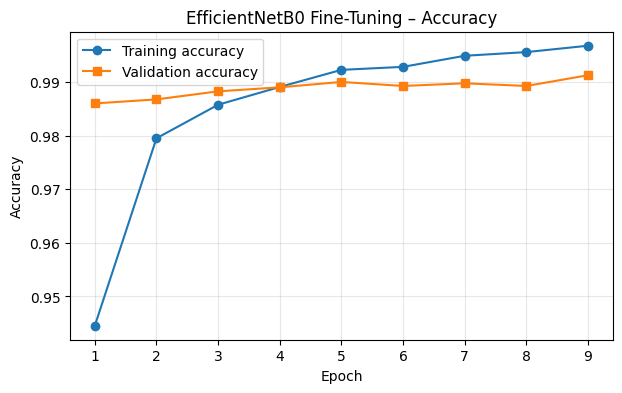

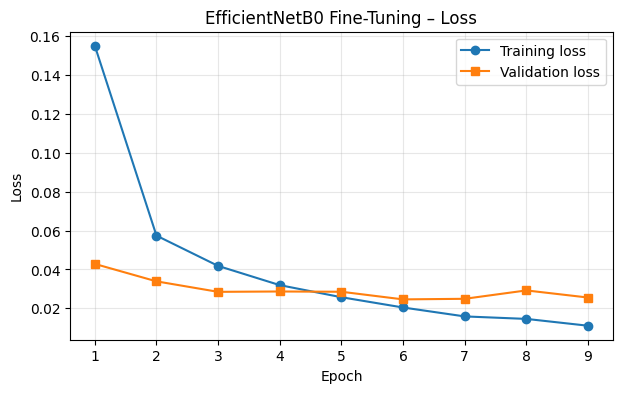

In [ ]:
plot_history(history_ft, "accuracy", "EfficientNetB0 Fine-Tuning")
plot_history(history_ft, "loss", "EfficientNetB0 Fine-Tuning")

### Feature extraction vs. full fine-tuning

| Aspect | Feature extraction | Full fine-tuning |
|---|---|---|
| **Trainable layers** | Only the new classification head | Every layer, backbone included |
| **Backbone weights** | Frozen – identical to ImageNet | Updated, adapted to the dog/cat data |
| **Trainable parameters** | Few (~160K) | All (millions) |
| **Training cost** | Low: fast, small memory footprint | High: slower, needs more GPU memory |
| **Learning rate** | Can be relatively large (1e-3) | Must be small (1e-4 – 1e-5) to avoid destroying pretrained features |
| **Overfitting risk** | Low | Higher, especially with little data |
| **Accuracy potential** | Good when the target domain resembles ImageNet | Usually higher, since features adapt to the specific task |
| **Best when** | Small dataset, limited compute, quick baseline | Larger dataset, domain differs from ImageNet, best accuracy needed |

**In short:** feature extraction treats the pretrained network as a fixed feature extractor and only learns a new decision layer on top of it, while full fine-tuning lets the entire network re-specialize its features for the new task, at a higher cost in compute and overfitting risk.

# Model Comparison

For a fair comparison, **training loss/accuracy are re-evaluated on the clean (un-augmented) training set** rather than taken from the last epoch of `history`, which was measured on augmented images with dropout active.
Precision, recall and F1 are computed on the test set with "dog" (label 1) as the positive class.

In [ ]:
def get_labels(dataset):
    "Collect ground-truth labels from a dataset as a flat int array."
    return np.concatenate([y.numpy().ravel() for _, y in dataset]).astype(int)

def evaluate_model(model, name):
    "Return a dict with every metric required in the comparison table."
    train_loss, train_acc = model.evaluate(train_ds, verbose=0)
    val_loss,   val_acc   = model.evaluate(val_ds,   verbose=0)
    test_loss,  test_acc  = model.evaluate(test_ds,  verbose=0)

    y_true = get_labels(test_ds)
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "Model": name,
        "Total Parameters": model.count_params(),
        "Training Loss": train_loss,
        "Training Accuracy": train_acc,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_acc,
        "Test Loss": test_loss,
        "Test Accuracy": test_acc,
        "Test Precision": precision_score(y_true, y_pred),
        "Test Recall": recall_score(y_true, y_pred),
        "Test F1 Score": f1_score(y_true, y_pred),
    }

models = {
    "Custom CNN": custom_cnn,
    "Feature Extraction (MobileNetV2)": feature_model,
    "Fine-Tuned (EfficientNetB0)": finetune_model,
}

results = [evaluate_model(m, name) for name, m in models.items()]
comparison_df = pd.DataFrame(results).set_index("Model")

# Metrics as rows, models as columns; parameters shown with thousands separators
table = comparison_df.T
formatted = table.copy().astype(object)
for metric in table.index:
    formatted.loc[metric] = [f"{int(v):,}" if metric == "Total Parameters" else f"{v:.4f}"
                             for v in table.loc[metric]]
display(formatted)

Model,Custom CNN,Feature Extraction (MobileNetV2),Fine-Tuned (EfficientNetB0)
Total Parameters,"1,208,545","2,422,081","4,050,852"
Training Loss,0.4627,0.0201,0.0063
Training Accuracy,0.7801,0.9927,0.9986
Validation Loss,0.4646,0.0362,0.0246
Validation Accuracy,0.7791,0.9872,0.9892
Test Loss,0.4616,0.0323,0.0292
Test Accuracy,0.7834,0.9884,0.9906
Test Precision,0.8084,0.9904,0.9881
Test Recall,0.7428,0.9864,0.9932
Test F1 Score,0.7742,0.9884,0.9906


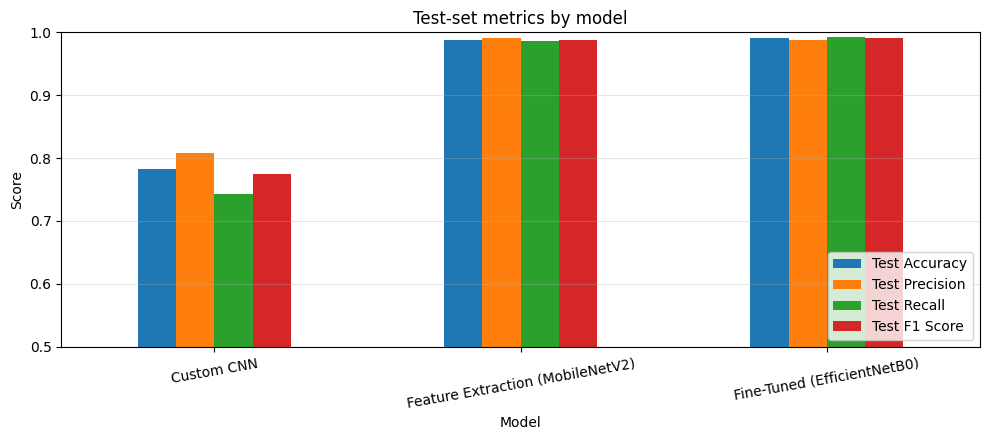

In [ ]:
# Visual comparison
metrics_to_plot = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1 Score"]
ax = comparison_df[metrics_to_plot].plot(kind="bar", figsize=(10, 4.5), rot=10)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("Score"); ax.set_title("Test-set metrics by model")
ax.grid(axis="y", alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Which model performed best?**
The fine-tuned **EfficientNetB0** performed best: test accuracy 99.06%, F1 0.9906, and the lowest test loss (0.0292). It made 47 errors on 5,000 test images. The MobileNetV2 feature-extraction model was very close (98.84% accuracy, 58 errors), while the custom CNN was far behind (78.34% accuracy, 1,083 errors).

**Which model is most computationally efficient?**
The **MobileNetV2 feature-extraction model** is the most efficient overall. It trains only 164K parameters (versus 1.2M for the custom CNN and 4.0M for the fine-tuned model), converged in 8 epochs, and MobileNetV2 is designed for low-cost inference. The custom CNN has the fewest total parameters (1.2M), but it applies convolutions at full 224×224 resolution in its early layers, so its per-image compute is higher than the pretrained models (my rough estimate is approx. 2.6 GMACs versus approx. 0.3 for MobileNetV2), and it is much less accurate. Training time per epoch was similar for all three (~215–260 s), most likely because the input/augmentation pipeline is the bottleneck.

**Which model would I deploy in production, and why?**
If accuracy matters most and a server or GPU is available, I would deploy the **fine-tuned EfficientNetB0**, since it has the highest accuracy and balanced precision/recall (0.988 / 0.993). For mobile or edge deployment, I would choose **MobileNetV2 feature extraction**: it is only 0.22 percentage points less accurate (11 more errors out of 5,000), smaller, and cheaper to run. I would not deploy the custom CNN.


# Error Analysis

`error_analysis(model, test_dataset, class_names)` is a reusable function that:
1. predicts on the test dataset,
2. prints a classification report,
3. plots a confusion matrix,
4. displays at least 9 misclassified images (the **most confidently wrong** ones) with actual label, predicted label, and prediction confidence.


In [ ]:
def error_analysis(model, test_dataset, class_names, n_images=9, threshold=0.5):
    """
    Evaluate a binary classifier on a test dataset and inspect its mistakes.

    Parameters
    ----------
    model        : trained Keras model with a single sigmoid output
    test_dataset : batched tf.data.Dataset yielding (images, labels), NOT shuffled
    class_names  : list like ['cats', 'dogs'] (index 0 = negative class, 1 = positive class)
    n_images     : number of misclassified images to display (>= 9 recommended)
    threshold    : decision threshold applied to the sigmoid output

    Returns
    -------
    dict with y_true, y_pred, y_prob and the indices of all misclassified samples
    """
    # Predict on the test dataset
    y_prob = model.predict(test_dataset, verbose=0).ravel()          # P(class_names[1])
    y_true = np.concatenate([y.numpy().ravel() for _, y in test_dataset]).astype(int)
    y_pred = (y_prob >= threshold).astype(int)

    # Classification report
    print("=" * 60)
    print(f"Classification report – {model.name}")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion matrix – {model.name}")
    plt.tight_layout(); plt.show()

    # Misclassified images
    wrong_idx = np.where(y_pred != y_true)[0]
    print(f"Misclassified: {len(wrong_idx)} / {len(y_true)} "
          f"({len(wrong_idx) / len(y_true):.2%})")
    if len(wrong_idx) == 0:
        print("No errors to display.")
        return {"y_true": y_true, "y_pred": y_pred, "y_prob": y_prob, "wrong_idx": wrong_idx}

    # Confidence = probability assigned to the PREDICTED class
    confidence = np.where(y_pred == 1, y_prob, 1.0 - y_prob)
    # Show the most confidently wrong predictions first
    chosen = wrong_idx[np.argsort(-confidence[wrong_idx])][:n_images]
    chosen_set = set(chosen.tolist())

    # Second pass over the dataset to pull out only the chosen images (saves memory)
    found, offset = {}, 0
    for images, _ in test_dataset:
        batch_size = images.shape[0]
        for j in range(batch_size):
            if offset + j in chosen_set:
                found[offset + j] = images[j].numpy()
        offset += batch_size
        if len(found) == len(chosen_set):
            break

    cols = 3
    rows = int(np.ceil(len(chosen) / cols))
    plt.figure(figsize=(4 * cols, 4.2 * rows))
    for k, idx in enumerate(chosen):
        img = found[idx]
        if img.max() > 1.0:                 # handle un-normalized [0, 255] datasets
            img = img / 255.0
        plt.subplot(rows, cols, k + 1)
        plt.imshow(np.clip(img, 0, 1))
        plt.title(f"Actual: {class_names[y_true[idx]]}\n"
                  f"Predicted: {class_names[y_pred[idx]]}\n"
                  f"Confidence: {confidence[idx]:.1%}", color="crimson", fontsize=11)
        plt.axis("off")
    plt.suptitle(f"Most confident misclassifications – {model.name}", fontsize=14)
    plt.tight_layout(); plt.show()

    return {"y_true": y_true, "y_pred": y_pred, "y_prob": y_prob, "wrong_idx": wrong_idx}

Classification report – custom_cnn
              precision    recall  f1-score   support

        cats     0.7621    0.8240    0.7919      2500
        dogs     0.8084    0.7428    0.7742      2500

    accuracy                         0.7834      5000
   macro avg     0.7853    0.7834    0.7830      5000
weighted avg     0.7853    0.7834    0.7830      5000



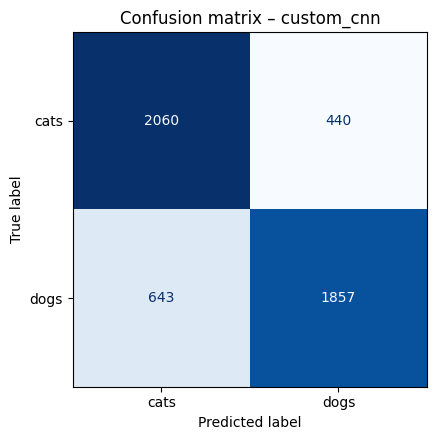

Misclassified: 1083 / 5000 (21.66%)


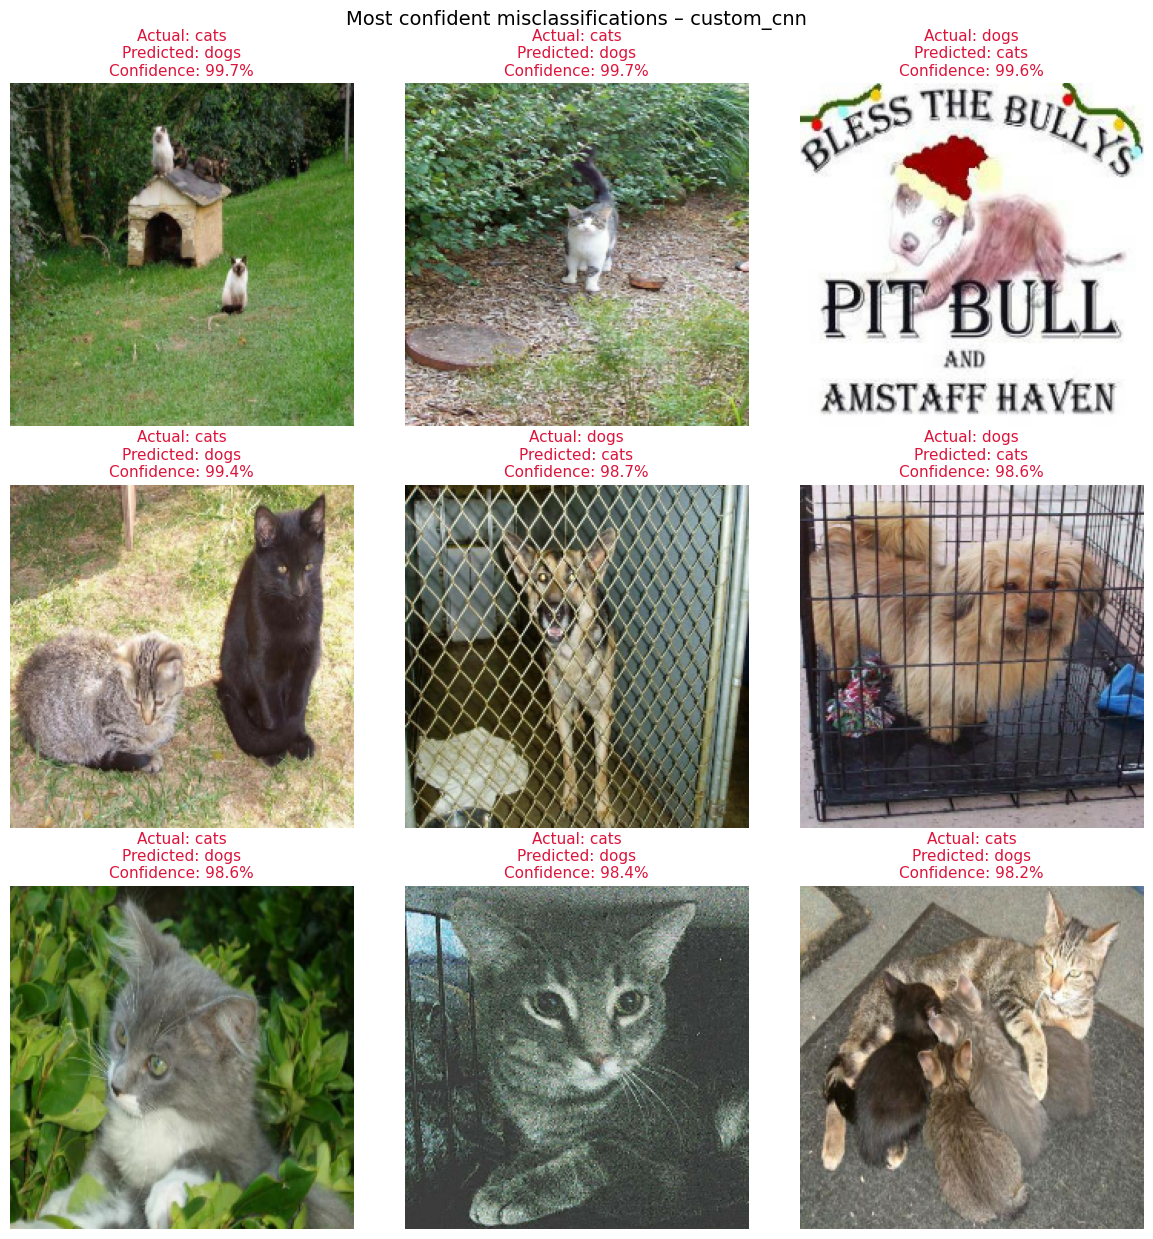

Classification report – mobilenetv2_feature_extraction
              precision    recall  f1-score   support

        cats     0.9865    0.9904    0.9884      2500
        dogs     0.9904    0.9864    0.9884      2500

    accuracy                         0.9884      5000
   macro avg     0.9884    0.9884    0.9884      5000
weighted avg     0.9884    0.9884    0.9884      5000



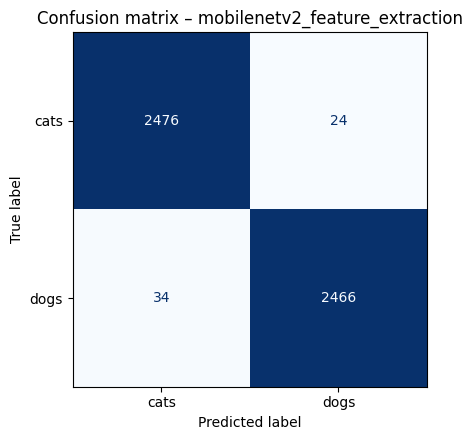

Misclassified: 58 / 5000 (1.16%)


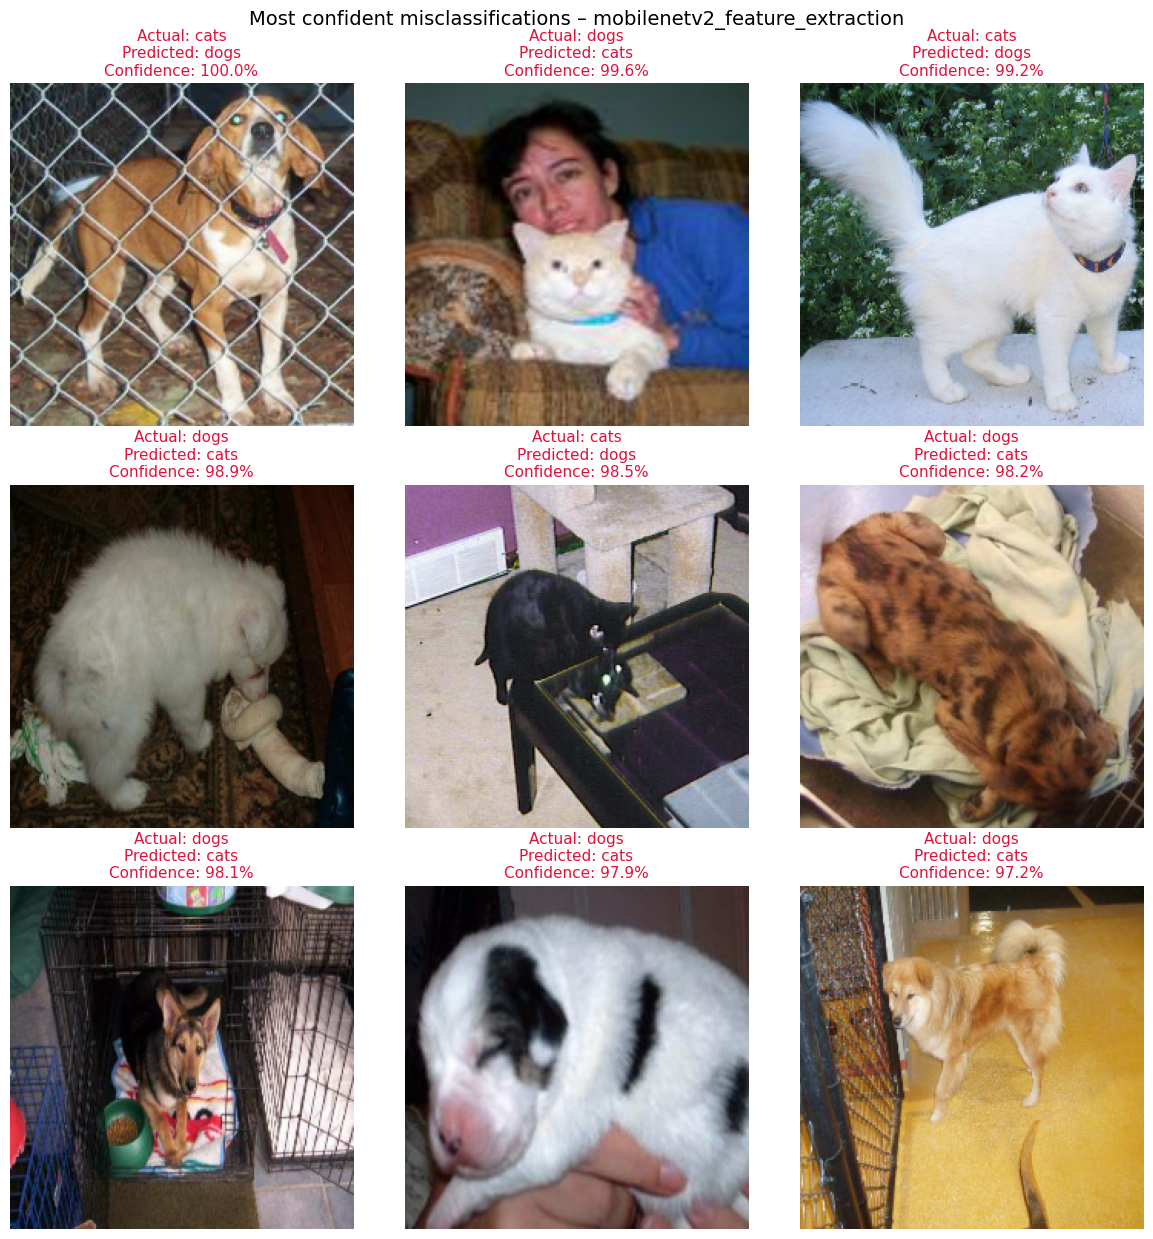

Classification report – efficientnetb0_finetuned
              precision    recall  f1-score   support

        cats     0.9932    0.9880    0.9906      2500
        dogs     0.9881    0.9932    0.9906      2500

    accuracy                         0.9906      5000
   macro avg     0.9906    0.9906    0.9906      5000
weighted avg     0.9906    0.9906    0.9906      5000



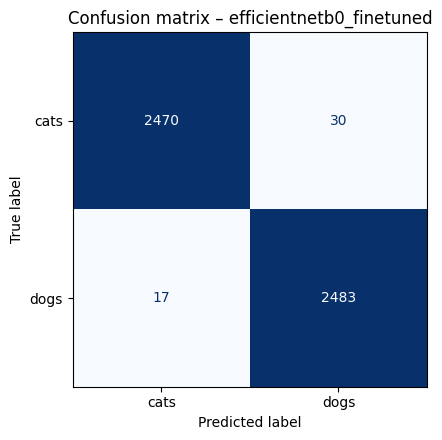

Misclassified: 47 / 5000 (0.94%)


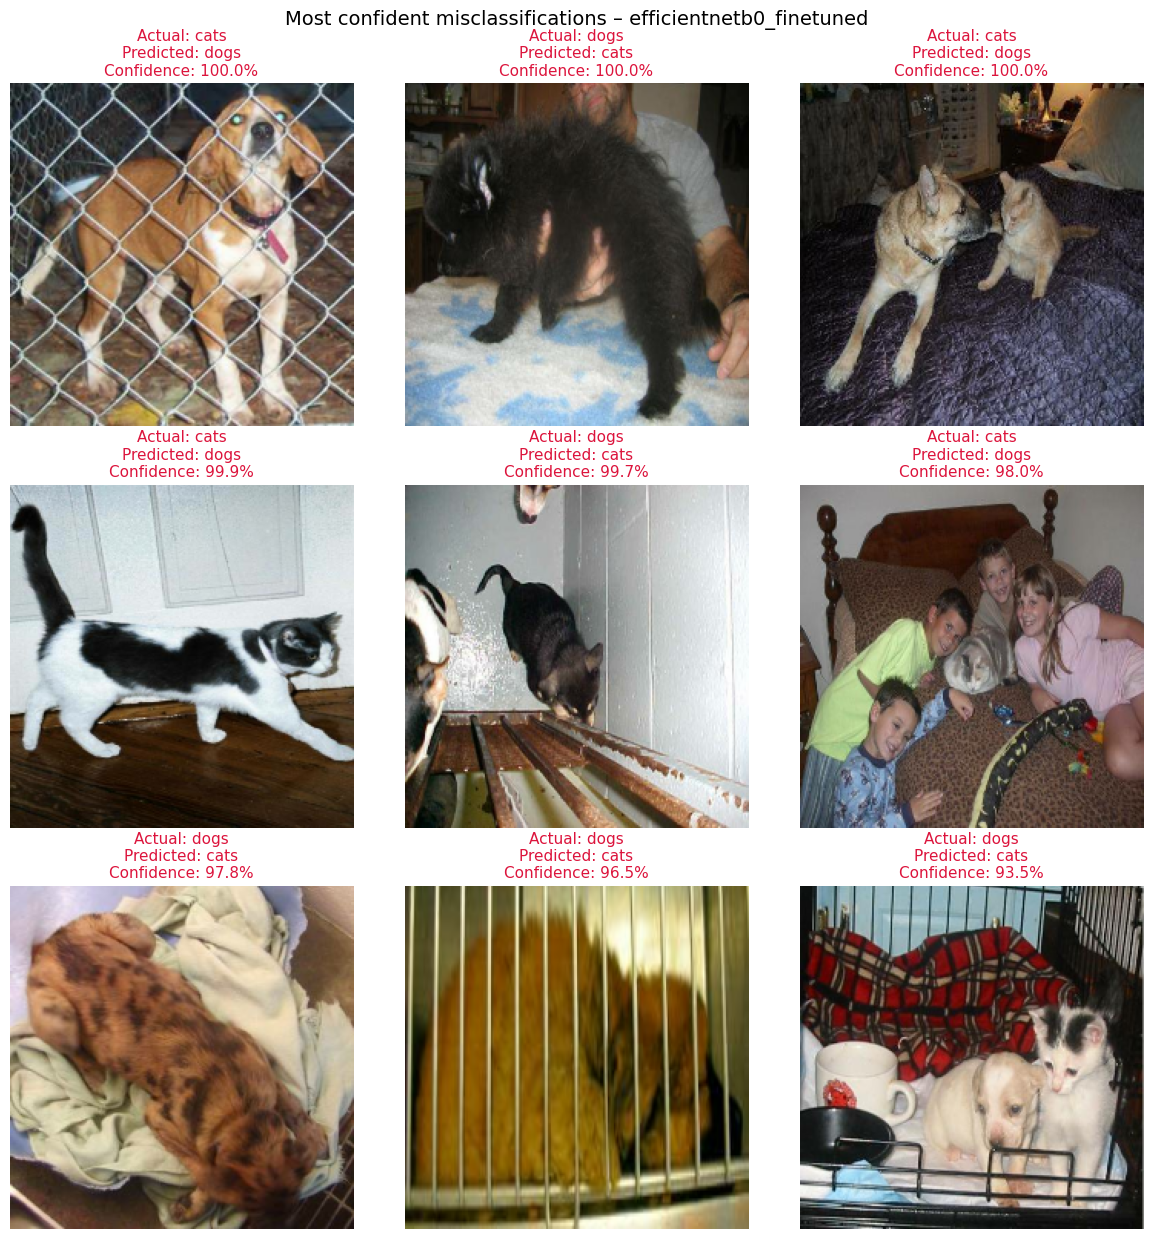

In [ ]:
# Error analysis
analysis_cnn = error_analysis(custom_cnn, test_ds, class_names)
analysis_fe = error_analysis(feature_model, test_ds, class_names)
analysis_ft = error_analysis(finetune_model, test_ds, class_names)

# Observations
- **Custom CNN:** 21.66% error rate (1,083 / 5,000). Its most confident mistakes include clearly recognizable cats predicted as dogs with ~99% confidence, so the model is simply under-trained (training accuracy was only 78%).
- **Pretrained models:** error rates drop to 1.16% (MobileNetV2) and 0.94% (EfficientNetB0), with balanced errors across both classes.
- **Their remaining errors** are mostly hard cases: animals behind cage bars or fences, puppies or kittens in close-ups, cats and dogs in the same image, small animals in cluttered scenes, and animals with unusual fur patterns.
- **Possible label noise:** the first image in both pretrained models' grids appears to be a dog labeled as "cats". Both models predicted "dogs" with ~100% confidence, so this may be a dataset labeling error rather than a model error.

# Conclusion

This project compared three approaches to dog-vs-cat classification on 25,000 images: a custom CNN trained from scratch, MobileNetV2 as a frozen feature extractor, and a fully fine-tuned EfficientNetB0.

The custom CNN reached 78.34% test accuracy (F1 0.7742). Its training accuracy was also only about 78%, so it was under-trained rather than overfit, and its validation curve was unstable. The two pretrained models performed far better. Feature extraction reached 98.84% test accuracy (F1 0.9884) by training only 164K parameters, and full fine-tuning reached the best result of 99.06% (F1 0.9906) with the lowest test loss (0.0292). The gap between the two pretrained models is small (47 vs. 58 errors out of 5,000), so most of the gain comes from using ImageNet features at all, and fine-tuning adds a modest improvement at a higher training cost.

Error analysis showed that the remaining mistakes of the pretrained models are mostly hard cases (cages and fences, close-ups of puppies or kittens, multiple animals, cluttered backgrounds) and likely include a few mislabeled images. The final choice depends on the deployment setting: the fine-tuned EfficientNetB0 for maximum accuracy on a server, and MobileNetV2 feature extraction when model size, speed, and cost matter, as on mobile devices. Possible improvements include test-time augmentation, ensembling the two pretrained models, higher input resolution, and cleaning mislabeled images.